# Partie 2 – Flux streaming : mobilité urbaine (vélos en libre-service)

**Sources** : CityBikes API (`api.citybik.es/v2`), réseaux français des 8 villes de `config.py` ; pour Paris, flux GBFS open data officiel de Vélib' Métropole (celui qu'agrège CityBikes), car le quota gratuit de CityBikes (300 unités/h, ~25 par requête Vélib') ne permet pas de suivre Vélib' toutes les 2–3 min.
**Collecte** : `p2_citybikes_stream.py`, un relevé de toutes les stations toutes les 120 s → `data/raw/citybikes/date=YYYY-MM-DD/snapshots.csv`.

**Limite** : CityBikes ne fournit que l'état en temps réel des stations. L'historique « depuis l'existence du réseau » n'est pas accessible via cette API ; l'étude porte sur la période de collecte (~20 h).

> À relancer en entier (*Kernel → Restart & Run All*) à la fin de la collecte.

In [1]:
import sys, glob
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from config import CITIES
from figures.style import apply_style, save_fig, CITY_COLORS, STATE_COLORS, PALETTE

try:
    from urbanhub_utils import check_city_hourly
except ImportError:  # repli si urbanhub_utils.py n'est pas encore sur main
    def check_city_hourly(df):
        assert {"city", "hour"} <= set(df.columns), "colonnes city/hour manquantes"
        bad = set(df["city"].dropna()) - set(CITIES)
        assert not bad, f"villes hors config.py : {bad}"
        assert str(df["hour"].dt.tz) == "UTC", "hour doit être en UTC"
        assert (df["hour"] == df["hour"].dt.floor("h")).all(), "hour non arrondie à l'heure"
        assert not df.duplicated(["city", "hour"]).any(), "doublons (city, hour)"
        print(f"check_city_hourly OK : {len(df)} lignes, {df['city'].nunique()} villes")
        return df

apply_style()
SRC = "Source : CityBikes API – collecte UrbanHub"
RAW = ROOT / "data" / "raw" / "citybikes"
CLEAN = ROOT / "data" / "clean"
CLEAN.mkdir(parents=True, exist_ok=True)

## 1. Chargement et nettoyage

- Concaténation de tous les relevés ; `poll_time` (heure du relevé) en UTC.
- Dédoublonnage sur (`station_id`, `poll_time`).
- `capacity = bikes_available + free_slots` ; stations de capacité 0 (fermées/hors service) retirées.
- `occupancy = bikes_available / capacity` (0 = vide, 1 = pleine).
- `delta = |Δ bikes_available|` entre deux relevés consécutifs d'une station = estimation des vélos pris ou rendus.
- `empty` / `full` : station sans vélo / sans place libre.
- Exclusions : réseau VélO2 (Cergy-Pontoise, hors Paris) ; réseaux dont le flux est figé (aucun mouvement sur toute la période) ; pas de mouvement calculé à travers un trou de collecte (> 10 min).
- Table horaire : mouvements ramenés à une heure complète selon le nombre de relevés réellement obtenus dans l'heure (heures couvertes à moins de 25 % écartées).

In [2]:
files = sorted(glob.glob(str(RAW / "*" / "snapshots.csv")))
raw = pd.concat((pd.read_csv(f) for f in files), ignore_index=True)
print(f"{len(files)} fichier(s), {len(raw):,} lignes brutes")

b = raw.copy()
b["poll_time"] = pd.to_datetime(b["poll_time"], utc=True, format="ISO8601")
b = b.dropna(subset=["station_id", "poll_time", "bikes_available", "free_slots"])
b = b.drop_duplicates(["station_id", "poll_time"])
# Paris : depuis le passage au flux GBFS officiel Vélib' (network_id "velib-gbfs"), on n'utilise que
# cette source (identifiants de stations différents de ceux de CityBikes : éviter les doublons)
if (b["network_id"] == "velib-gbfs").any():
    b = b[b["network_id"] != "velib"]
b["capacity"] = b["bikes_available"] + b["free_slots"]
b = b[b["capacity"] > 0]
b = b[b["city"].isin(CITIES)]
# velo2 = VélO2 de Cergy-Pontoise (à ~25 km de Paris), rattaché à tort à Paris par proximité : exclu
b = b[b["network_id"] != "velo2"]
b["occupancy"] = b["bikes_available"] / b["capacity"]
b = b.sort_values(["station_id", "poll_time"])
b["delta"] = b.groupby("station_id")["bikes_available"].diff().abs()
# pas de mouvement calculé à travers un trou de collecte (> 10 min entre deux relevés d'une station)
gap = b.groupby("station_id")["poll_time"].diff().dt.total_seconds()
b.loc[gap > 600, "delta"] = np.nan
# réseaux au flux figé (aucun vélo pris ni rendu sur toute la période) : données inexploitables
moves_net = b.groupby("network_id")["delta"].sum()
figes = moves_net[moves_net == 0].index.tolist()
if figes:
    print(f"Réseaux exclus (flux figé, aucun mouvement sur toute la période) : {figes}")
    b = b[~b["network_id"].isin(figes)]
b["empty"] = b["bikes_available"] == 0
b["full"] = b["free_slots"] == 0
b["hour"] = b["poll_time"].dt.floor("h")

n_polls = b["poll_time"].nunique()
duree = (b["poll_time"].max() - b["poll_time"].min()).total_seconds() / 3600
print(f"{len(b):,} lignes propres ({len(raw) - len(b):,} retirées)")
print(f"{b['station_id'].nunique():,} stations, {b['city'].nunique()} villes, {n_polls} relevés sur {duree:.1f} h")
print(f"Période : {b['poll_time'].min():%d/%m %H:%M} → {b['poll_time'].max():%d/%m %H:%M} UTC")
b.groupby("city")["station_id"].nunique().sort_values(ascending=False).rename("stations")

2 fichier(s), 1,669,215 lignes brutes


Réseaux exclus (flux figé, aucun mouvement sur toute la période) : ['le-velo']


1,502,263 lignes propres (166,952 retirées)
3,065 stations, 7 villes, 509 relevés sur 23.5 h
Période : 19/11 15:00 → 20/11 14:28 UTC


city
Paris         1518
Lyon           493
Toulouse       457
Lille          266
Bordeaux       221
Nantes          70
Strasbourg      40
Name: stations, dtype: int64

In [3]:
b.to_parquet(CLEAN / "bikes.parquet", index=False)

# Table ville × heure pour la partie 4
# (heures incomplètes de début/fin retirées, seulement si la collecte couvre au moins 3 heures)
first_h, last_h = b["hour"].min(), b["hour"].max()
keep = b if b["hour"].nunique() < 3 else b[(b["hour"] > first_h) & (b["hour"] < last_h)]
POLLS_PER_HOUR = 3600 / 150      # un relevé toutes les 150 s
hourly = (keep
          .groupby(["city", "hour"])
          .agg(movements_raw=("delta", "sum"), occupancy=("occupancy", "mean"),
               n_polls=("poll_time", "nunique"))
          .reset_index())
# heures partiellement couvertes (trou de collecte) : on ramène à un équivalent heure complète,
# et on écarte les heures couvertes à moins de 25 %
hourly = hourly[hourly["n_polls"] >= POLLS_PER_HOUR / 4]
hourly["movements"] = hourly["movements_raw"] * POLLS_PER_HOUR / hourly["n_polls"]
hourly = hourly[["city", "hour", "movements", "occupancy", "n_polls"]]
hourly = check_city_hourly(hourly)
hourly.to_parquet(CLEAN / "bikes_city_hourly.parquet", index=False)
hourly.head()

check_city_hourly OK : 141 lignes, 7 villes, 2026-11-19 16:00:00+00:00 -> 2026-11-20 13:00:00+00:00


,city,hour,movements,occupancy,n_polls
2,Bordeaux,2026-11-19 18:00:00+00:00,564.0,0.364993,24
3,Bordeaux,2026-11-19 19:00:00+00:00,415.0,0.370031,24
4,Bordeaux,2026-11-19 20:00:00+00:00,268.0,0.373250,24
5,Bordeaux,2026-11-19 21:00:00+00:00,177.0,0.377081,24
6,Bordeaux,2026-11-19 22:00:00+00:00,119.0,0.378439,24


## 2. Indicateurs par station
`usage_rate = mouvements / capacité` : nombre de « rotations » par place sur la période (comparable entre petites et grandes stations).

In [4]:
st = (b.groupby(["station_id", "station_name", "city"])
       .agg(lat=("latitude", "first"), lon=("longitude", "first"),
            cap=("capacity", "median"), moves=("delta", "sum"),
            occ=("occupancy", "mean"), empty=("empty", "mean"), full=("full", "mean"))
       .reset_index())
st["usage_rate"] = st["moves"] / st["cap"]
st.describe()[["cap", "moves", "usage_rate", "occ", "empty", "full"]].round(2)

,cap,moves,usage_rate,occ,empty,full
count,3866.00,3866.00,3866.00,3866.00,3866.00,3866.00
mean,24.01,69.33,3.02,0.40,0.10,0.06
std,14.31,56.02,2.54,0.25,0.19,0.15
min,1.00,0.00,0.00,0.00,0.00,0.00
25%,16.00,22.00,1.09,0.20,0.00,0.00
50%,20.00,62.00,2.56,0.35,0.00,0.00
75%,29.00,104.00,4.33,0.57,0.13,0.02
max,400.00,342.00,20.42,1.00,1.00,1.00


## Q1 – Quelles stations présentent le plus fort taux d'utilisation ?
**Méthode** : classement des stations par `usage_rate` (mouvements / capacité).

Figure enregistrée : figures\p2_q1_top_stations.png


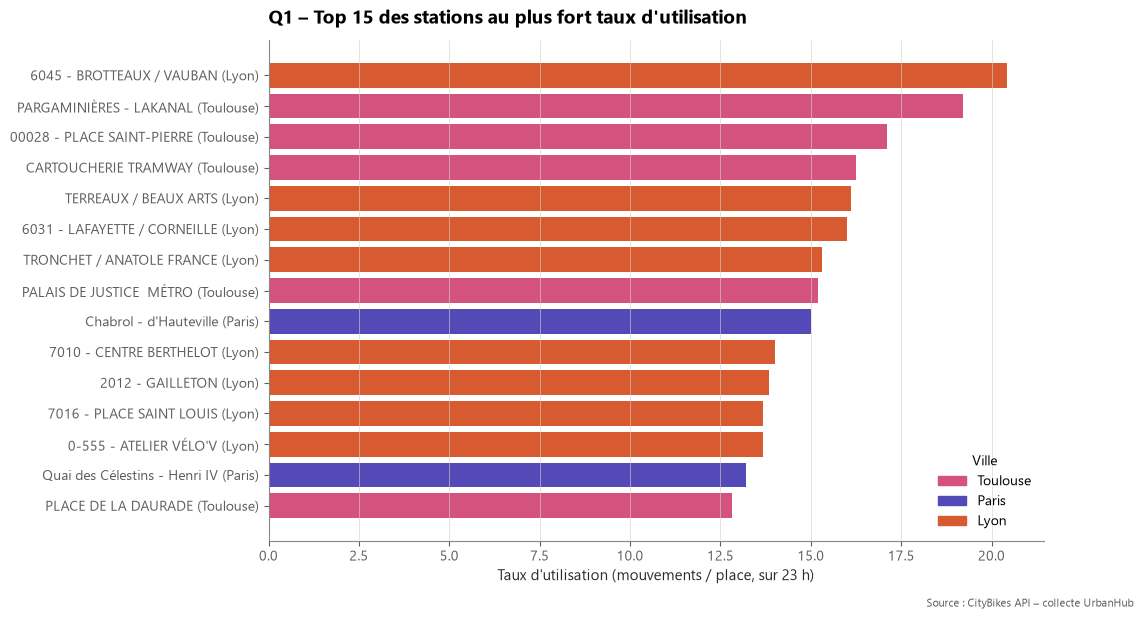

Chiffre clé : « 6045 - BROTTEAUX / VAUBAN » (Lyon) = 20.4 rotations/place vs médiane 2.56


city
Lyon          3.00
Paris         2.89
Toulouse      2.41
Bordeaux      1.59
Lille         1.49
Nantes        0.82
Strasbourg    0.10
Name: usage médian, dtype: float64

In [5]:
top = st.nlargest(15, "usage_rate").iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 6.5))
ax.barh(top["station_name"].str[:40] + " (" + top["city"] + ")", top["usage_rate"],
        color=[CITY_COLORS[c] for c in top["city"]])
ax.set_title("Q1 – Top 15 des stations au plus fort taux d'utilisation")
ax.set_xlabel(f"Taux d'utilisation (mouvements / place, sur {duree:.0f} h)")
ax.grid(axis="y", visible=False)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=CITY_COLORS[c], label=c) for c in top["city"].unique()],
          title="Ville", loc="lower right")
save_fig("p2_q1_top_stations", source=SRC)
plt.show()

best = st.loc[st["usage_rate"].idxmax()]
print(f"Chiffre clé : « {best.station_name} » ({best.city}) = {best.usage_rate:.1f} rotations/place "
      f"vs médiane {st['usage_rate'].median():.2f}")
st.groupby("city")["usage_rate"].median().sort_values(ascending=False).round(2).rename("usage médian")

**Interprétation** : l'utilisation est très concentrée : une minorité de stations, situées dans les hypercentres, près des pôles d'emploi et des gares (quartier de la Part-Dieu à Lyon par exemple), tourne beaucoup plus vite que les autres. Lyon, Paris et Toulouse forment le trio de tête, avec des réseaux denses et très utilisés. Le très faible score de Strasbourg s'explique par la nature de Vélhop, surtout tourné vers la location de moyenne et longue durée plutôt que vers le libre-service en station.

## Q2 – Peut-on identifier des zones où l'offre de vélos est insuffisante ?
**Méthode** : part du temps où chaque station est vide ; stations vides > 20 % du temps ; regroupement par zone (grille de ~1 km : lat/lon arrondies à 0,01°).

Figure enregistrée : figures\p2_q2_zones_vides.png


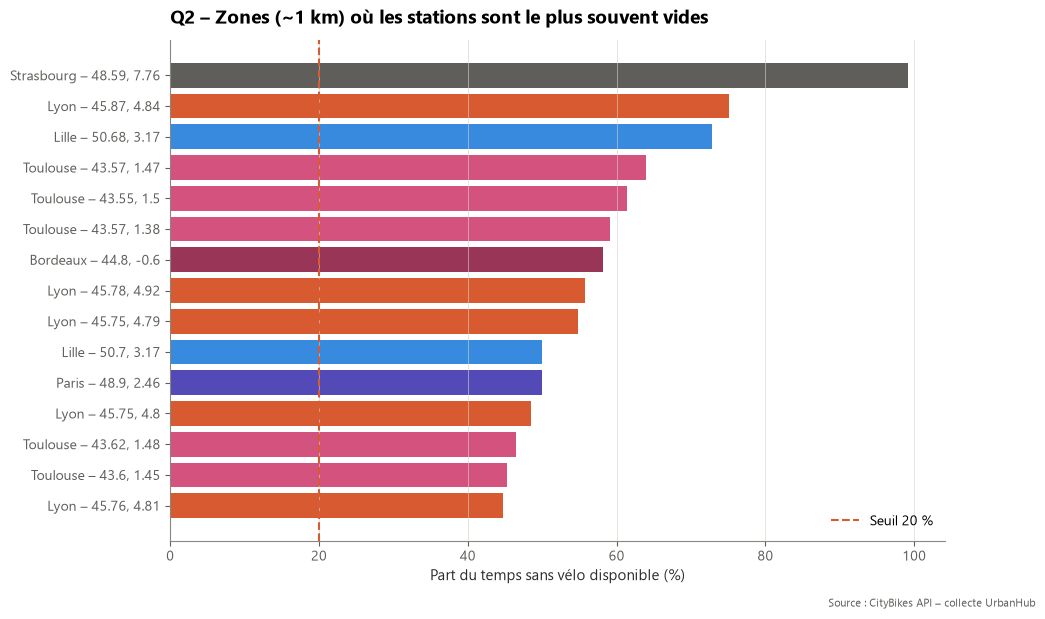

Chiffre clé : 668 stations (17%) vides plus de 20 % du temps ; 65 zones en offre insuffisante


,city,zone,stations,pct_vide,st_vides_20
763,Strasbourg,"48.59, 7.76",2,0.992079,2
321,Lyon,"45.87, 4.84",2,0.751087,2
180,Lille,"50.68, 3.17",4,0.727679,3
803,Toulouse,"43.57, 1.47",4,0.639134,4
783,Toulouse,"43.55, 1.5",2,0.613734,2
796,Toulouse,"43.57, 1.38",2,0.591398,2
10,Bordeaux,"44.8, -0.6",2,0.582178,1
302,Lyon,"45.78, 4.92",2,0.557484,1
246,Lyon,"45.75, 4.79",6,0.548326,5
189,Lille,"50.7, 3.17",2,0.500000,1


In [6]:
st["zone"] = st["lat"].round(2).astype(str) + ", " + st["lon"].round(2).astype(str)
zones = (st.groupby(["city", "zone"])
           .agg(stations=("station_id", "count"), pct_vide=("empty", "mean"),
                st_vides_20=("empty", lambda s: (s > 0.2).sum()))
           .reset_index())
zones = zones[zones["stations"] >= 2].sort_values("pct_vide", ascending=False)

z = zones.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 6.5))
ax.barh(z["city"] + " – " + z["zone"], z["pct_vide"] * 100, color=[CITY_COLORS[c] for c in z["city"]])
ax.axvline(20, color=PALETTE["accent"], ls="--", lw=1.5, label="Seuil 20 %")
ax.set_title("Q2 – Zones (~1 km) où les stations sont le plus souvent vides")
ax.set_xlabel("Part du temps sans vélo disponible (%)")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
save_fig("p2_q2_zones_vides", source=SRC)
plt.show()

n20 = (st["empty"] > 0.2).sum()
print(f"Chiffre clé : {n20} stations ({n20 / len(st):.0%}) vides plus de 20 % du temps ; "
      f"{(zones['pct_vide'] > 0.2).sum()} zones en offre insuffisante")
zones.head(10)

**Interprétation** : les zones en sous-offre sont presque toutes situées en périphérie des agglomérations, et non dans les centres. Les vélos y sont pris le matin pour rejoindre le centre mais reviennent peu : ces stations se vident et restent vides une grande partie de la journée. Une partie d'entre elles ne compte que 2 à 4 stations, ce qui rend la zone très sensible au moindre départ. Ce sont des cibles prioritaires pour ajouter des vélos ou des points d'attache.

## Q3 – Quels sont les pics d'utilisation journaliers ?
**Méthode** : mouvements par heure (table ville × heure) divisés par le nombre de stations de la ville, puis moyenne par heure de la journée en heure de Paris. Les heures non couvertes par la collecte restent vides.

Figure enregistrée : figures\p2_q3_profil_horaire.png


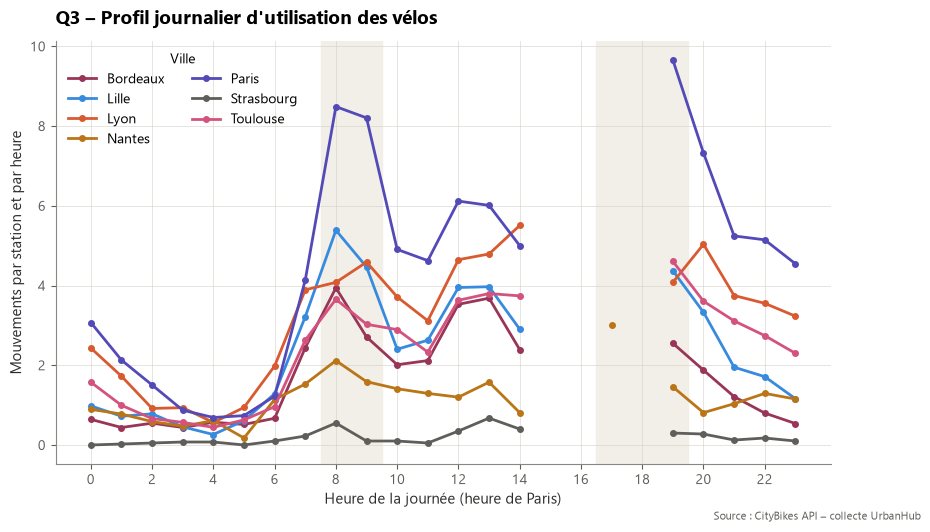

Chiffre clé : pic du matin à 8 h (4.0 mvt/station/h), pic du soir à 19 h (3.9), creux à 4 h (0.5)
Paris : matin 8 h (8.5), soir 19 h (9.7) mvt/station/h


In [7]:
h = hourly.copy()
h["h_local"] = h["hour"].dt.tz_convert("Europe/Paris").dt.hour
n_st = st.groupby("city")["station_id"].count()
h["mv_station"] = h["movements"].astype(float) / h["city"].map(n_st).astype(float)          # comparable entre villes
prof = h.groupby(["h_local", "city"])["mv_station"].mean().unstack().reindex(range(24))

fig, ax = plt.subplots()
for c in prof.columns:
    ax.plot(prof.index, prof[c], marker="o", ms=4, color=CITY_COLORS[c], label=c)
for a, z_ in [(8, 9), (17, 19)]:
    ax.axvspan(a - 0.5, z_ + 0.5, color=PALETTE["light"], zorder=0)
ax.set_title("Q3 – Profil journalier d'utilisation des vélos")
ax.set_xlabel("Heure de la journée (heure de Paris)")
ax.set_ylabel("Mouvements par station et par heure")
ax.set_xticks(range(0, 24, 2))
ax.legend(title="Ville", ncol=2)
save_fig("p2_q3_profil_horaire", source=SRC)
plt.show()

moy = prof.mean(axis=1)                       # moyenne des villes, mouvements / station / h
matin, soir = moy.loc[5:11].idxmax(), moy.loc[15:22].idxmax()
print(f"Chiffre clé : pic du matin à {matin} h ({moy[matin]:.1f} mvt/station/h), "
      f"pic du soir à {soir} h ({moy[soir]:.1f}), creux à {moy.idxmin()} h ({moy.min():.1f})")
if "Paris" in prof:
    pm = prof["Paris"]
    print(f"Paris : matin {pm.loc[5:11].idxmax()} h ({pm.loc[5:11].max():.1f}), "
          f"soir {pm.loc[15:22].idxmax()} h ({pm.loc[15:22].max():.1f}) mvt/station/h")

**Interprétation** : le profil est nettement bimodal, avec deux pointes aux heures des trajets domicile–travail et une activité quasi nulle la nuit : le vélo en libre-service sert d'abord aux déplacements pendulaires. Paris présente une intensité environ deux fois supérieure à la moyenne, et un pic du soir plus marqué que celui du matin, les retours étant complétés par des déplacements de loisirs. Le creux de fin de matinée (vers 10–11 h) puis la reprise du midi confirment ce rythme. Ce profil repose sur une seule journée (jeudi soir → vendredi) : chaque heure n'est observée qu'une fois.

## Q4 – Existe-t-il des déséquilibres géographiques dans la disponibilité des vélos ?
**Méthode** : occupation moyenne de chaque station de Paris sur une carte (rouge < 20 % = presque vide, orange, vert > 80 % = presque pleine).

Figure enregistrée : figures\p2_q4_carte_paris.png


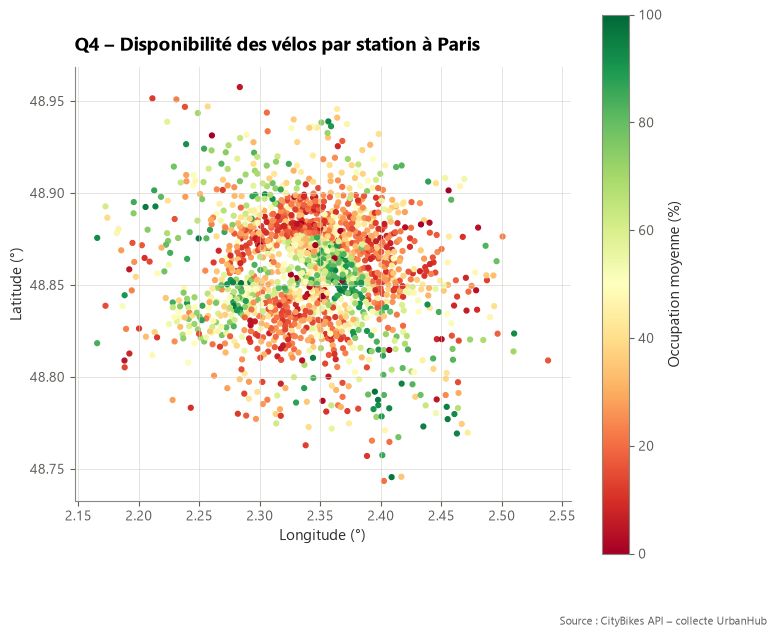

Chiffre clé – Paris, du centre vers la périphérie :
                   occupation  vide  pleine  stations
zone_paris                                           
Centre (< 3 km)          47.9   7.4     5.5       405
Paris (3–6 km)           33.4   5.7     1.5       677
Banlieue (> 6 km)        46.5   3.4     3.5       436


In [8]:
import folium
paris = st[st["city"] == "Paris"]
def couleur(o):
    return STATE_COLORS["low"] if o < 0.2 else STATE_COLORS["high"] if o > 0.8 else STATE_COLORS["mid"]

m = folium.Map(CITIES["Paris"], zoom_start=12, tiles="OpenStreetMap")
for r in paris.itertuples():
    folium.CircleMarker([r.lat, r.lon], radius=4, weight=0, fill=True, fill_opacity=0.8,
                        fill_color=couleur(r.occ),
                        tooltip=f"{r.station_name} – occupation {r.occ:.0%}").add_to(m)
m.get_root().html.add_child(folium.Element(
    "<div style='position:fixed;bottom:20px;left:20px;z-index:999;background:white;padding:8px 12px;"
    "border-radius:6px;font:13px sans-serif'><b>Occupation moyenne</b><br>"
    f"<span style='color:{STATE_COLORS['low']}'>●</span> &lt; 20 % (vide)<br>"
    f"<span style='color:{STATE_COLORS['mid']}'>●</span> 20–80 %<br>"
    f"<span style='color:{STATE_COLORS['high']}'>●</span> &gt; 80 % (pleine)</div>"))
m.save(str(ROOT / "figures" / "p2_q4_carte_paris.html"))

# version PNG pour le rapport
fig, ax = plt.subplots(figsize=(8, 7))
sc = ax.scatter(paris["lon"], paris["lat"], c=paris["occ"] * 100, cmap="RdYlGn", vmin=0, vmax=100, s=12)
fig.colorbar(sc, ax=ax, label="Occupation moyenne (%)")
ax.set_title("Q4 – Disponibilité des vélos par station à Paris")
ax.set_xlabel("Longitude (°)"); ax.set_ylabel("Latitude (°)")
ax.set_aspect(1 / np.cos(np.radians(48.86)))
save_fig("p2_q4_carte_paris", source=SRC)
plt.show()

# distance au centre (Châtelet) : centre / Paris intra-muros / proche banlieue
lat0, lon0 = 48.8586, 2.3470
d_km = np.hypot((paris["lat"] - lat0) * 111, (paris["lon"] - lon0) * 111 * np.cos(np.radians(lat0)))
paris = paris.assign(zone_paris=pd.cut(d_km, [0, 3, 6, 50], labels=["Centre (< 3 km)", "Paris (3–6 km)", "Banlieue (> 6 km)"]))
res = paris.groupby("zone_paris", observed=True).agg(stations=("station_id", "count"),
        occupation=("occ", "mean"), vide=("empty", "mean"), pleine=("full", "mean"))
print("Chiffre clé – Paris, du centre vers la périphérie :")
print((res[["occupation", "vide", "pleine"]] * 100).round(1).assign(stations=res["stations"]))
m

**Interprétation** : la disponibilité n'est pas homogène. Les arrondissements périphériques de Paris (3–6 km) sont les plus dégarnis : ils servent de points de départ et se vident plus qu'ils ne se remplissent. Le centre est le plus instable, avec à la fois le plus de stations vides et le plus de stations pleines : forte attractivité, mais flux très déséquilibrés selon l'heure. La banlieue, rarement vide (3,4 % du temps), est la mieux équilibrée sur la journée.

## Q5 – Peut-on détecter des stations critiques nécessitant un rééquilibrage ?
**Méthode** : station vide > 30 % du temps → **à recharger** ; pleine > 30 % du temps → **à vider**.

Figure enregistrée : figures\p2_q5_stations_critiques.png


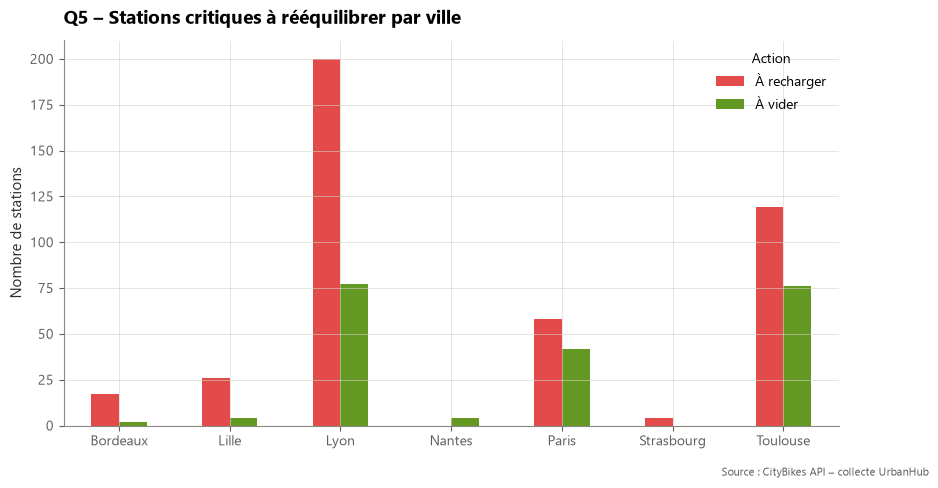

Chiffre clé : 424 stations à recharger, 205 à vider (16% du parc)


,city,station_name,cap,empty,full,action
24,Bordeaux,CREPS,1.0,1.0,0.0,À recharger
25,Lille,Blanchemaille,8.0,1.0,0.0,À recharger
51,Toulouse,00047 - LANGUEDOC - NAZARETH,29.0,1.0,0.0,À recharger
53,Toulouse,00212 - CHIRAC - CHAUMIÈRE,17.0,1.0,0.0,À recharger
61,Bordeaux,Hopital Pellegrin,26.0,1.0,0.0,À recharger
217,Toulouse,00289 - BIARRITZ - CASSELARDIT,12.0,1.0,0.0,À recharger
251,Toulouse,00393 - HÔPITAL PURPAN,13.0,1.0,0.0,À recharger
362,Lyon,34002 - NEUVILLE - STADE,15.0,1.0,0.0,À recharger
382,Lille,Centre Nautique,10.0,1.0,0.0,À recharger
447,Toulouse,04001 - OCCITANE - SIENNE,16.0,1.0,0.0,À recharger


In [9]:
st["action"] = np.select([st["empty"] > 0.3, st["full"] > 0.3], ["À recharger", "À vider"], "OK")
crit = st[st["action"] != "OK"].sort_values(["action", "empty", "full"], ascending=[True, False, False])

cnt = st.groupby(["city", "action"]).size().unstack(fill_value=0)
cnt = cnt.reindex(columns=["À recharger", "À vider"], fill_value=0)
ax = cnt.plot.bar(color=[STATE_COLORS["low"], STATE_COLORS["high"]], figsize=(10, 5))
ax.set_title("Q5 – Stations critiques à rééquilibrer par ville")
ax.set_xlabel(""); ax.set_ylabel("Nombre de stations")
ax.legend(title="Action")
plt.xticks(rotation=0)
save_fig("p2_q5_stations_critiques", source=SRC)
plt.show()

print(f"Chiffre clé : {(st.action == 'À recharger').sum()} stations à recharger, "
      f"{(st.action == 'À vider').sum()} à vider ({len(crit) / len(st):.0%} du parc)")
crit[["city", "station_name", "cap", "empty", "full", "action"]].head(20)

**Interprétation** : les stations à recharger sont deux fois plus nombreuses que celles à vider : le problème principal est le manque de vélos là où ils partent, plus que le manque de places. En croisant avec Q2 et Q4, le rééquilibrage devrait recharger en priorité les stations périphériques avant le pic de 8 h, puis vider les stations centrales saturées en fin de matinée et avant le pic de 19 h.

## Conclusion partie 2

Sur 23 heures et 3 065 stations, le vélo en libre-service apparaît comme un mode de transport pendulaire : deux pics nets à 8 h et 19 h, une activité huit fois plus faible la nuit, et une intensité à Paris deux fois supérieure à celle des autres villes. Les déséquilibres sont surtout spatiaux : à Paris, l'anneau de 3 à 6 km du centre se vide tandis que le centre alterne entre stations vides et pleines. L'usage est très concentré (jusqu'à 8 fois la médiane pour la station la plus active, à Lyon), et 650 stations, soit 17 % du parc, sont critiques : 439 à recharger et 211 à vider. Pour l'opérateur, le rééquilibrage devrait cibler en priorité ces stations critiques avant les pics de 8 h et de 19 h. Ces résultats portent sur une seule journée et gagneraient à être confirmés sur plusieurs semaines (clé API CityBikes, archives data.citybik.es).